# Train from your manually sorted folders — no labeling interface

On your computer create **BabyTraining/back**, **BabyTraining/side**, **BabyTraining/prone**, and optional **BabyTraining/unknown**. Copy about 100 varied images into each posture folder to start, keep filenames/image contents, then compress the parent folder into **BabyTraining.zip**. Do not create train/test folders.

Your folder choices are the labels. This notebook accepts that ZIP, extracts MediaPipe's original **12 metrics**, trains **ONE posture classifier**, reports measured results, and can export the existing live box/risk/alarm handoff. It does not use MobileNet or notebook review widgets.

**A small pilot is not proof of 95%.** Posture risk is not an airway/SIDS probability. [Full manual-folder instructions](https://github.com/kg905/SeniorDesignProject/blob/main/docs/MANUAL_FOLDERS.md). Choose a CPU runtime and run cells in order.


## 1. Get the code and original grouping reference
A sparse checkout avoids downloading all 5,814 source images again. Existing checkouts are fast-forwarded without deleting local data.

In [1]:
import os, subprocess, sys
from pathlib import Path
ROOT = Path('/content/SeniorDesignProject')
GIT_ENV = dict(os.environ, GIT_LFS_SKIP_SMUDGE='1')
if not ROOT.exists():
    subprocess.run(['git', 'clone', '--depth', '1', '--filter=blob:none', '--sparse',
                    'https://github.com/kg905/SeniorDesignProject.git', str(ROOT)], env=GIT_ENV, check=True)
    subprocess.run(['git', 'sparse-checkout', 'set', 'src', 'training', 'deploy/single-model',
                    'docs', 'models', 'artifacts/dataset_audit_v2'], cwd=ROOT, env=GIT_ENV, check=True)
else:
    subprocess.run(['git', 'pull', '--ff-only'], cwd=ROOT, env=GIT_ENV, check=True)
os.chdir(ROOT)
print('Source ready:', ROOT)


Source ready: /content/SeniorDesignProject


## 2. Install dependencies

This affects this temporary Colab runtime, not your Pi. Keep only one pip cv2 distribution. If Colab requests a restart, restart after installation, rerun section 1, then continue to section 3. Do not skip an unsuccessful install.


In [2]:
%pip uninstall -y opencv-python opencv-python-headless opencv-contrib-python opencv-contrib-python-headless
%pip install -r /content/SeniorDesignProject/training/requirements.txt
%pip install --no-deps -e /content/SeniorDesignProject
!apt-get update -qq
!apt-get install -y -qq git-lfs libgles2 libegl1 libgl1 libportaudio2


Found existing installation: opencv-contrib-python 4.12.0.88
Uninstalling opencv-contrib-python-4.12.0.88:
  Successfully uninstalled opencv-contrib-python-4.12.0.88
  Using cached opencv_contrib_python-4.12.0.88-cp37-abi3-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (19 kB)
Using cached opencv_contrib_python-4.12.0.88-cp37-abi3-manylinux2014_x86_64.manylinux_2_17_x86_64.whl (73.2 MB)
Obtaining file:///content/SeniorDesignProject
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for cribwatch-research (pyproject.toml) ... done
  Created wheel for cribwatch-research: filename=cribwatch_research-0.2.0-0.editable-py3-none-any.whl size=1826 sha256=6765631c5b1c5570538adcb8f6d1c235ef8e97acbb2c30eca63c9589471cc26f
  Stored in directory: /tmp/pip-ephem-wheel-cache-uxhnpcmh/wheels/fa/fb/d0/378ff6676d6e3bb42d6

## 3. Save this run to Drive and upload your SORTED ZIP
Upload BabyTraining.zip, not the original unsorted Roboflow ZIP. If already in Drive, fill ZIP_IN_DRIVE below to avoid another browser upload. Existing review CSVs/previous runs are not overwritten.

In [5]:
import os, sys, json, subprocess
from pathlib import Path

ROOT = Path('/content/SeniorDesignProject')
os.chdir(ROOT)

subprocess.run(
    ['git', 'pull', '--ff-only'],
    env=dict(os.environ, GIT_LFS_SKIP_SMUDGE='1'),
    check=True
)

from google.colab import files
import sys, importlib
sys.path.insert(0, "/content/SeniorDesignProject/src")
importlib.invalidate_caches()
from cribwatch.colab_io import local_zip_run

RUN, ZIP_PATH = local_zip_run()
print('Verified local ZIP:', ZIP_PATH)
print('Local run:', RUN)

Saving BabyTraining.zip to BabyTraining.zip
Verified local ZIP: /content/cribwatch-runs/run-20261027-221751-6cd4e3/incoming/BabyTraining.zip
Local run: /content/cribwatch-runs/run-20261027-221751-6cd4e3


## 4. Import folders as labels and check counts

The importer accepts one enclosing BabyTraining folder (or direct class folders). It verifies images, preserves your labels, keeps unknowns out of posture training, and quarantines conflicting copies. Hash matches to the original audit preserve known duplicate/source groups; new images get conservative duplicate grouping. None of this invents baby IDs.


In [6]:
from cribwatch.assets import safe_unzip
from cribwatch.folder_data import import_folders
from cribwatch.data import read_csv
EXTRACTED = RUN / 'sorted-images'
safe_unzip(ZIP_PATH, EXTRACTED)
AUDIT = RUN / 'folder-audit'
summary = import_folders(EXTRACTED, AUDIT, reference_index=ROOT / 'artifacts/dataset_audit_v2/images.csv')
print('Your folder counts:', summary['folder_counts'])
print('Eligible exact-unique posture images:', summary['eligible_unique_counts'])
print('Matched to original audit:', summary['matched_original_images'])
print('Conservative source groups:', summary['source_groups'])
print('Conflicting images excluded:', summary['conflicting_images'])
print('Ignored files:', summary['ignored_files'][:10])
if summary['conflicting_images']:
    print('Inspect', AUDIT / 'conflicts.json', 'and correct the computer folders for a future run.')
if any(summary['eligible_unique_counts'].get(label, 0) == 0 for label in ['back','side','prone']):
    raise ValueError('Need non-conflicting images in ALL THREE posture folders before training.')
MANIFEST = AUDIT / 'images.csv'
print('Labels saved:', MANIFEST)


Your folder counts: {'back': 104, 'prone': 102, 'side': 103, 'unknown': 13}
Eligible exact-unique posture images: {'back': 102, 'prone': 101, 'side': 101}
Matched to original audit: 322
Conservative source groups: 306
Conflicting images excluded: 4
Ignored files: []
Inspect /content/cribwatch-runs/run-20261027-221751-6cd4e3/folder-audit/conflicts.json and correct the computer folders for a future run.
Labels saved: /content/cribwatch-runs/run-20261027-221751-6cd4e3/folder-audit/images.csv


## 5. Verify MediaPipe assets and extract all 12 metrics
Only the two official pose/face assets are needed. They are fetched through Git LFS and checked against pinned SHA256 hashes. No labeling widgets are involved.

In [9]:
import os, sys, subprocess, importlib
from pathlib import Path

ROOT = Path("/content/SeniorDesignProject")
sys.path.insert(0, str(ROOT / "src"))

print("Getting the fix...", flush=True)
subprocess.run(
    ["git", "pull", "--ff-only"],
    cwd=ROOT,
    env=dict(os.environ, GIT_LFS_SKIP_SMUDGE="1",
             GIT_TERMINAL_PROMPT="0"),
    check=True, timeout=120,
)

import cribwatch.assets as assets
import cribwatch.data as data
importlib.reload(assets)
importlib.reload(data)

print("Downloading/verifying MediaPipe models...", flush=True)
assets.download_models(
    ROOT / "models",
    names=["pose_landmarker_lite.task", "face_landmarker.task"],
)

FEATURES = Path(RUN) / "features.csv"
if not FEATURES.exists():
    data.extract_manifest(MANIFEST, FEATURES, ROOT / "models", workers=1)

print("Section 5 complete. Continue to Section 6.")

Getting the fix...
Downloading/verifying MediaPipe models...
Verified pose_landmarker_lite.task: 5,777,746 bytes
Verified face_landmarker.task: 3,758,596 bytes
Extraction: 0/322 images saved; 322 remaining
Initializing MediaPipe pose and face tasks...
MediaPipe ready; processing images...
Extracted 1/322 images
Extracted 10/322 images
Extracted 20/322 images
Extracted 30/322 images
Extracted 40/322 images
Extracted 50/322 images
Extracted 60/322 images
Extracted 70/322 images
Extracted 80/322 images
Extracted 90/322 images
Extracted 100/322 images
Extracted 110/322 images
Extracted 120/322 images
Extracted 130/322 images
Extracted 140/322 images
Extracted 150/322 images
Extracted 160/322 images
Extracted 170/322 images
Extracted 180/322 images
Extracted 190/322 images
Extracted 200/322 images
Extracted 210/322 images
Extracted 220/322 images
Extracted 230/322 images
Extracted 240/322 images
Extracted 250/322 images
Extracted 260/322 images
Extracted 270/322 images
Extracted 280/322 ima

In [8]:
from pathlib import Path
import csv, time

checkpoint = Path(RUN) / "features.csv.checkpoint.jsonl"

with open(MANIFEST) as f:
    total = sum(1 for _ in csv.DictReader(f))

completed = 0
if checkpoint.exists():
    with checkpoint.open() as f:
        completed = max(0, sum(1 for _ in f) - 1)
    age = (time.time() - checkpoint.stat().st_mtime) / 60
    print(f"Last saved progress: {age:.1f} minutes ago")

print(f"Images processed: {completed}/{total}")
print("Final features saved:", (Path(RUN) / "features.csv").exists())

for name in ["pose_landmarker_lite.task", "face_landmarker.task"]:
    p = Path(ROOT) / "models" / name
    print(name, p.stat().st_size if p.exists() else "MISSING")

Images processed: 0/322
Final features saved: False
pose_landmarker_lite.task 132
face_landmarker.task 132


## 6. Train ONE classifier and read the actual results

Default `source_groups` is an exploratory pilot. Code makes about 60/20/20 train/validation/test splits, keeping known related images together. It needs enough groups/classes; many augmented copies of one image do not supply that diversity. A split error means add varied sources, not bypass the guard.

Only use `baby_ids` with actual identities and recording metadata in optional metadata.csv; never invent them. A final claim requires a fresh independently reviewed held-out cohort. Unknown predictions count as errors. Do not repeatedly tune against a final test score.


In [10]:
from cribwatch.learning import train
EVALUATION_MODE = 'source_groups'
if EVALUATION_MODE not in ['source_groups', 'baby_ids']:
    raise ValueError('Use source_groups or baby_ids')
MODEL = RUN / 'model'
report = train(FEATURES, MODEL, exploratory=(EVALUATION_MODE == 'source_groups'))
print('Overall accuracy (unknown = error):', f"{report['accuracy_all_images_unknown_counts_as_error']:.1%}")
print('Prediction coverage:', f"{report['coverage']:.1%}")
for label, values in report['per_class'].items():
    print(label, 'recall:', f"{values['recall']:.1%}")
print('95% group-bootstrap interval:', report['accuracy_95ci_group_cluster_bootstrap'])
print('Report:', MODEL / 'test.json')
if not report['research_95pct_point_target_met']:
    print('95% TARGET NOT ESTABLISHED. This is a research pilot, not a validated infant-safety result.')


Overall accuracy (unknown = error): 14.5%
Prediction coverage: 21.0%
back recall: 30.4%
side recall: 10.5%
prone recall: 0.0%
95% group-bootstrap interval: [0.06153846153846154, 0.2459016393442623]
Report: /content/cribwatch-runs/run-20261027-221751-6cd4e3/model/test.json
95% TARGET NOT ESTABLISHED. This is a research pilot, not a validated infant-safety result.


## 7. See example scans with a pose box and risk level

These are examples after evaluation, not a new accuracy test. Body position maps to lower/moderate/high posture risk; unknown stays unknown. The visible-landmark box is not a separate baby/airway detector. Confidence is not a medical-risk percentage.


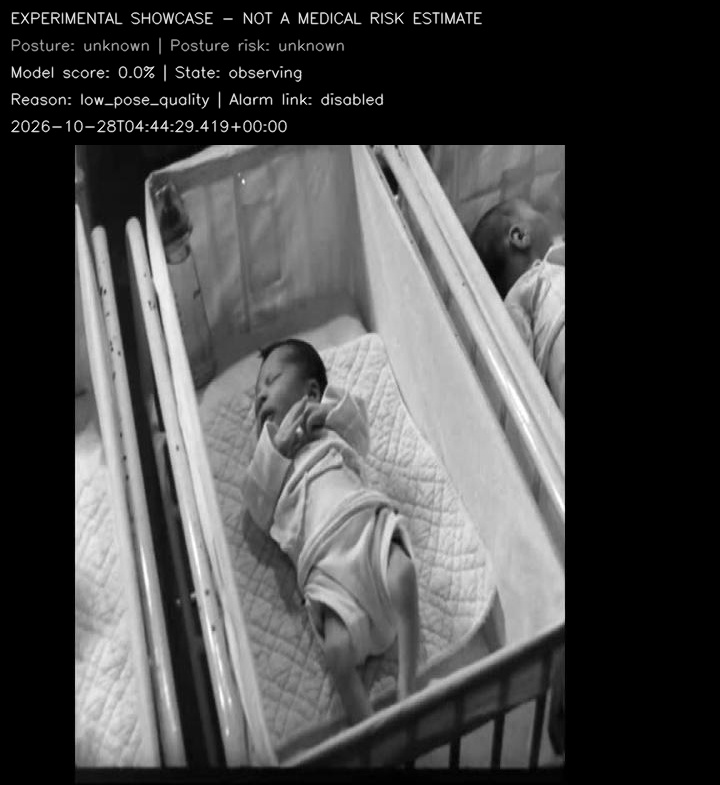

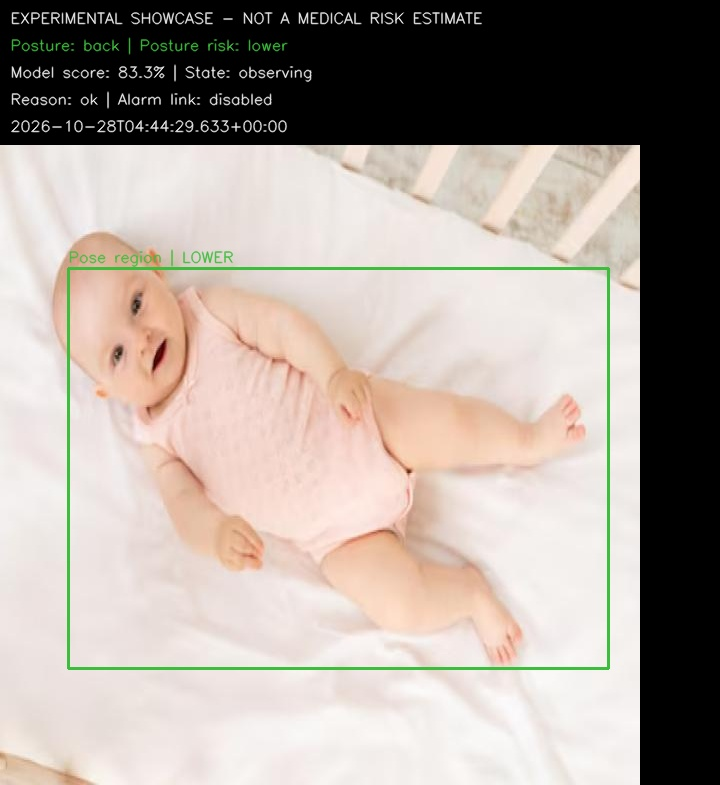

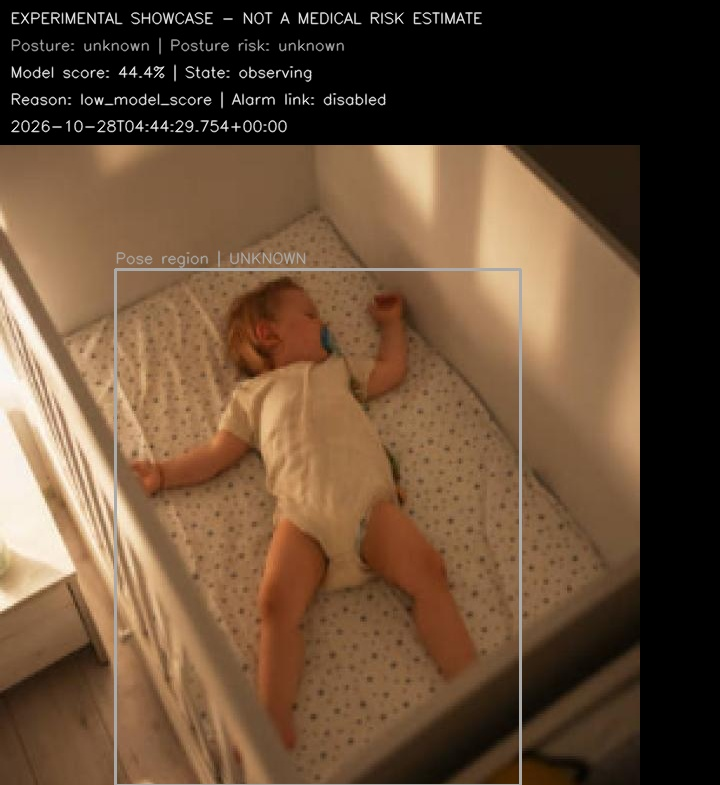

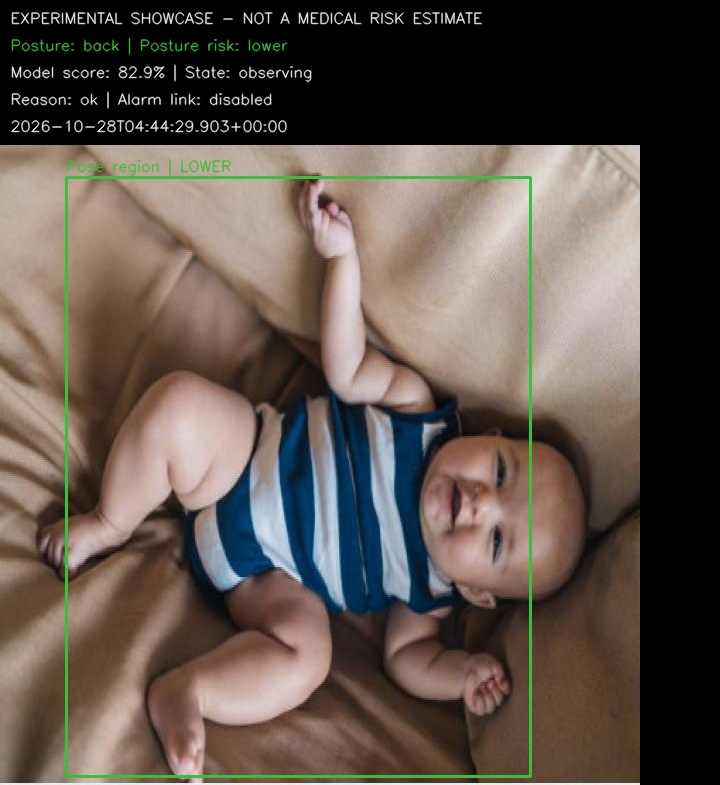

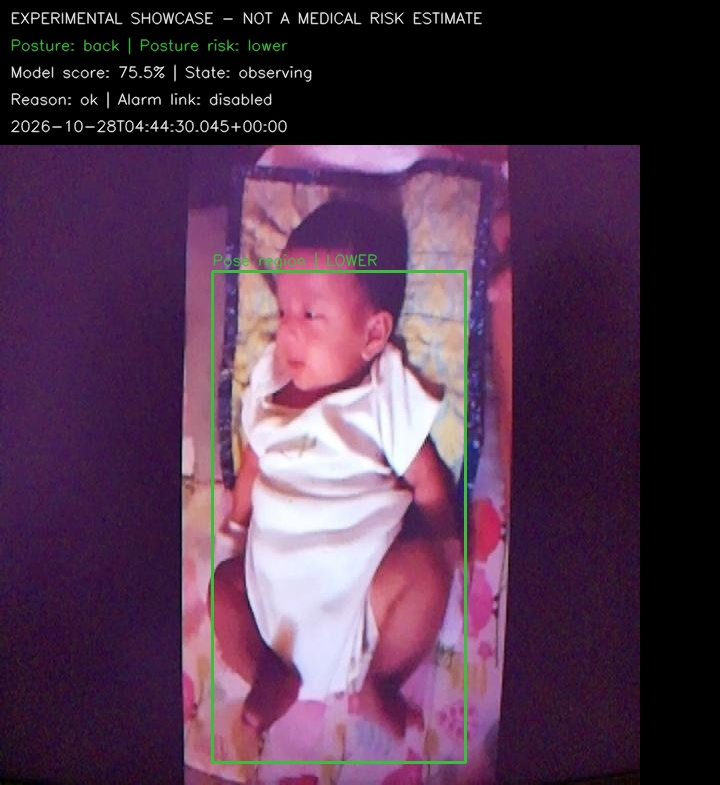

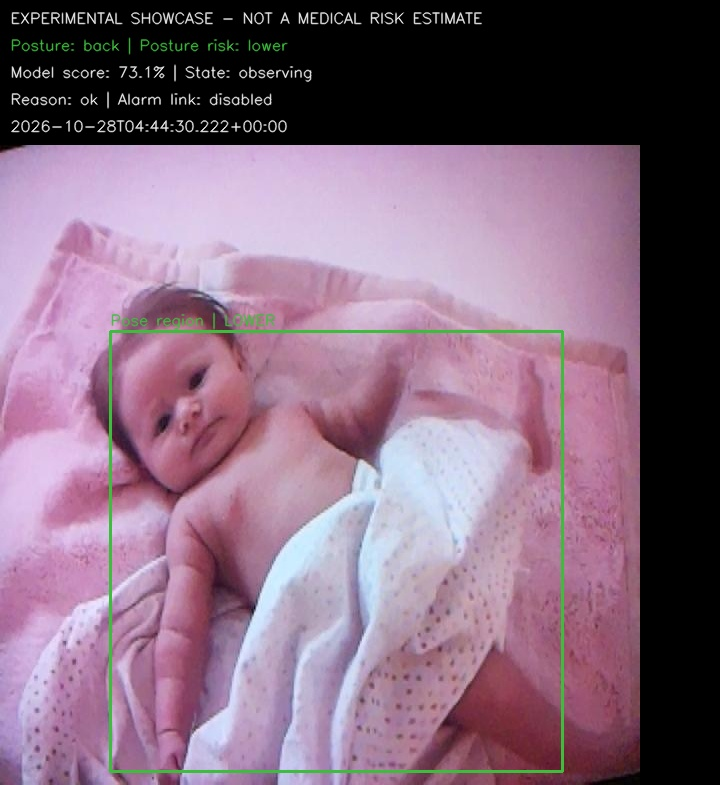

In [11]:
examples = [r['image_path'] for r in read_csv(MODEL / 'test_predictions.csv')][:6]
ANNOTATED = RUN / 'annotated-scans'
subprocess.run([sys.executable, '-m', 'cribwatch.showcase', 'image', '--model', str(MODEL / 'posture.joblib'),
                '--models', str(ROOT / 'models'), '--showcase', '--output', str(ANNOTATED), *examples], check=True)
from IPython.display import display
from PIL import Image
for image in sorted(ANNOTATED.glob('*.jpg')):
    display(Image.open(image))


## 8. Export the actual trained/evaluated Pi package
This packages one posture classifier, MediaPipe assets, report, scan/receiver scripts and instructions. It does not fabricate a 95% model or V10 artifacts. Physical Pi camera/GPIO/Wi-Fi and continuous-event tests remain necessary.

In [12]:
ZIP_OUT = RUN / 'SIDS_Pi5_Deployment.zip'
subprocess.run([sys.executable, str(ROOT / 'deploy/single-model/build_handoff.py'),
                '--model', str(MODEL), '--output', str(ZIP_OUT)], check=True)
files.download(str(ZIP_OUT))
print('Also in Drive:', ZIP_OUT)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Also in Drive: /content/cribwatch-runs/run-20261027-221751-6cd4e3/SIDS_Pi5_Deployment.zip


## Adding more images later

Add photos to the same class folders on your computer, create a ZIP of the entire updated BabyTraining folder, and start a new run. The new run imports your current folder choices and leaves old runs intact; adding files does not automatically retrain a deployed model. The original review-widget CSV is not needed for this workflow.

After installation on the Pi desktop, the package supports:

```bash
python monitor_pi5.py --model models --models models --picamera --display --showcase --alarm-risk moderate
```

Adopt the bundled TCP 5000 Pi 4 receiver and shared-key contract before adding `--alarm-host <Pi4-IP>`. Verify actual sound, risk timing, latching/mute/acknowledgement and camera/network faults. The attached PDF's V10 notebook/receiver source were not supplied; compatibility with unseen code is not claimed. Live screenshots demonstrate operation; only independent evaluation can support a 95% posture claim. No SIDS-prevention claim is made.
